# Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib

warnings.filterwarnings("ignore")

%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


# Load dataset

In [3]:
# Load dataset
df = pd.read_csv(r"C:\Users\ankit\Desktop\student id.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (705, 13)


,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status,Conflicts_Over_Social_Media,Addicted_Score
0,1,19,Female,Undergraduate,Bangladesh,5.2,Instagram,Yes,6.5,6,In Relationship,3,8
1,2,22,Male,Graduate,India,2.1,Twitter,No,7.5,8,Single,0,3
2,3,20,Female,Undergraduate,USA,6.0,TikTok,Yes,5.0,5,Complicated,4,9
3,4,18,Male,High School,UK,3.0,YouTube,No,7.0,7,Single,1,4
4,5,21,Male,Graduate,Canada,4.5,Facebook,Yes,6.0,6,In Relationship,2,7


# Understand the dataset

In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Number of rows: 705
Number of columns: 13

Column names:
['Student_ID', 'Age', 'Gender', 'Academic_Level', 'Country', 'Avg_Daily_Usage_Hours', 'Most_Used_Platform', 'Affects_Academic_Performance', 'Sleep_Hours_Per_Night', 'Mental_Health_Score', 'Relationship_Status', 'Conflicts_Over_Social_Media', 'Addicted_Score']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 705 entries, 0 to 704
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Student_ID                    705 non-null    int64  
 1   Age                           705 non-null    int64  
 2   Gender                        705 non-null    object 
 3   Academic_Level                705 non-null    object 
 4   Country                       705 non-null    object 
 5   Avg_Daily_Usage_Hours         705 non-null    float64
 6   Most_Used_Platform            705 non-null    object 
 7   Affects_Academic_Per

# Check missing values and duplicates

In [5]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
Student_ID                      0
Age                             0
Gender                          0
Academic_Level                  0
Country                         0
Avg_Daily_Usage_Hours           0
Most_Used_Platform              0
Affects_Academic_Performance    0
Sleep_Hours_Per_Night           0
Mental_Health_Score             0
Relationship_Status             0
Conflicts_Over_Social_Media     0
Addicted_Score                  0
dtype: int64

Duplicate rows:
0


# Remove duplicates

In [6]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (705, 13)


# Statistical summary

In [7]:
df.describe(include="all")

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status,Conflicts_Over_Social_Media,Addicted_Score
count,705.000000,705.000000,705,705,705,705.000000,705,705,705.000000,705.000000,705,705.000000,705.000000
unique,NaN,NaN,2,3,110,NaN,12,2,NaN,NaN,3,NaN,NaN
top,NaN,NaN,Female,Undergraduate,India,NaN,Instagram,Yes,NaN,NaN,Single,NaN,NaN
freq,NaN,NaN,353,353,53,NaN,249,453,NaN,NaN,384,NaN,NaN
mean,353.000000,20.659574,NaN,NaN,NaN,4.918723,NaN,NaN,6.868936,6.226950,NaN,2.849645,6.436879
std,203.660256,1.399217,NaN,NaN,NaN,1.257395,NaN,NaN,1.126848,1.105055,NaN,0.957968,1.587165
min,1.000000,18.000000,NaN,NaN,NaN,1.500000,NaN,NaN,3.800000,4.000000,NaN,0.000000,2.000000
25%,177.000000,19.000000,NaN,NaN,NaN,4.100000,NaN,NaN,6.000000,5.000000,NaN,2.000000,5.000000
50%,353.000000,21.000000,NaN,NaN,NaN,4.800000,NaN,NaN,6.900000,6.000000,NaN,3.000000,7.000000
75%,529.000000,22.000000,NaN,NaN,NaN,5.800000,NaN,NaN,7.700000,7.000000,NaN,4.000000,8.000000


# Check target variable

In [9]:
target = "Addicted_Score"

print("Target variable:", target)

print("\nTarget statistics:")
print(df[target].describe())

Target variable: Addicted_Score

Target statistics:
count    705.000000
mean       6.436879
std        1.587165
min        2.000000
25%        5.000000
50%        7.000000
75%        8.000000
max        9.000000
Name: Addicted_Score, dtype: float64


# Distribution of addiction score

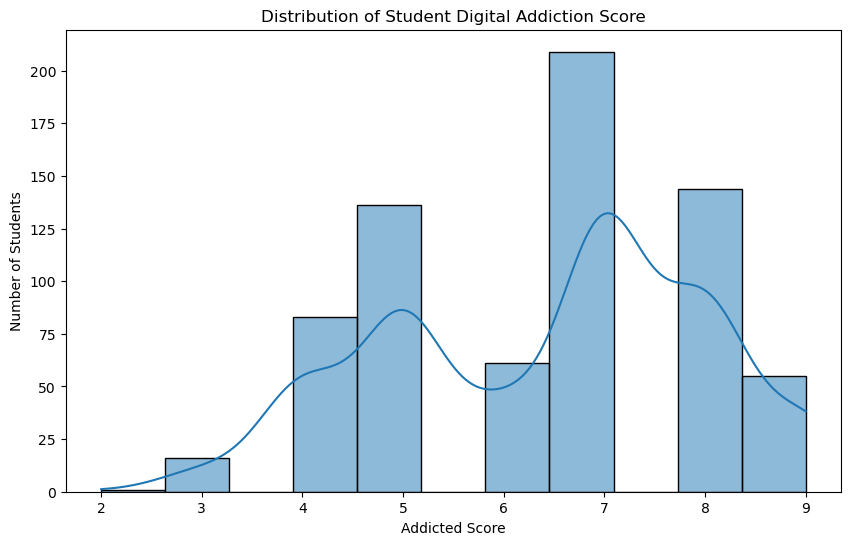

In [10]:
plt.figure(figsize=(10, 6))

sns.histplot(
    df["Addicted_Score"],
    kde=True
)

plt.title("Distribution of Student Digital Addiction Score")
plt.xlabel("Addicted Score")
plt.ylabel("Number of Students")

plt.show()

# Correlation analysis

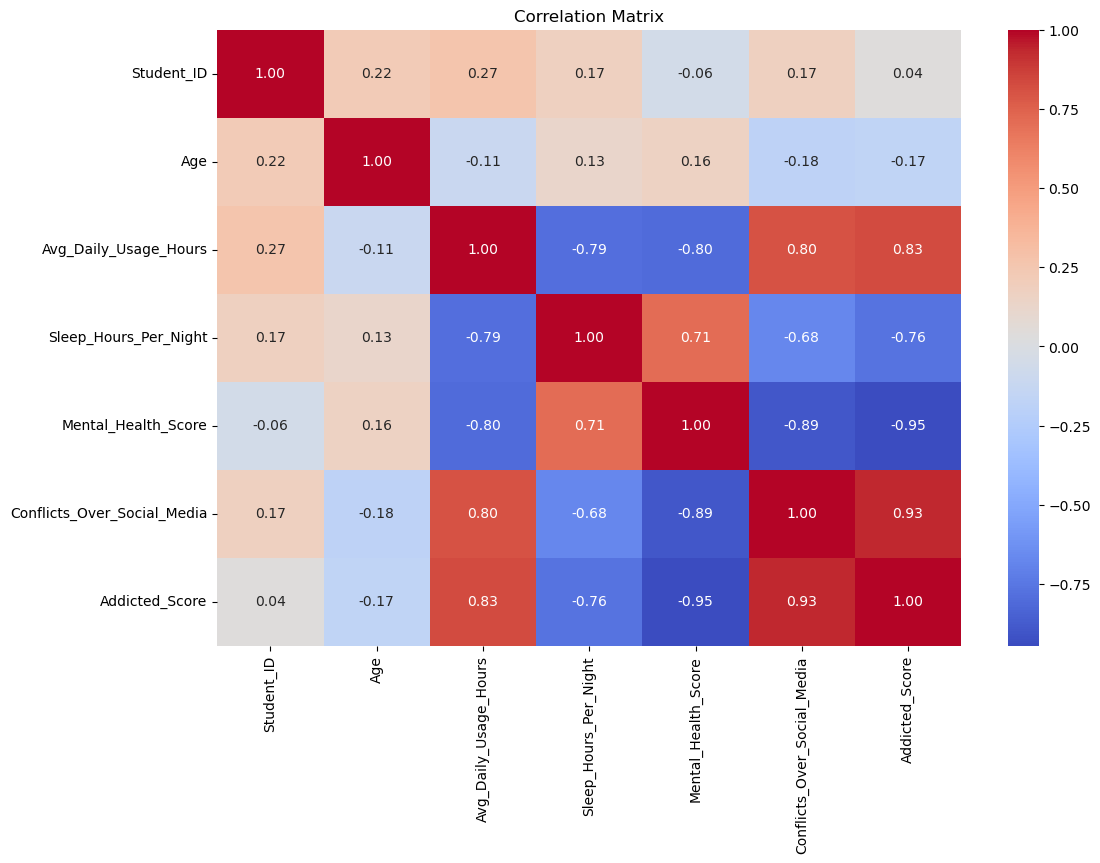

In [11]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

# Daily usage vs addiction

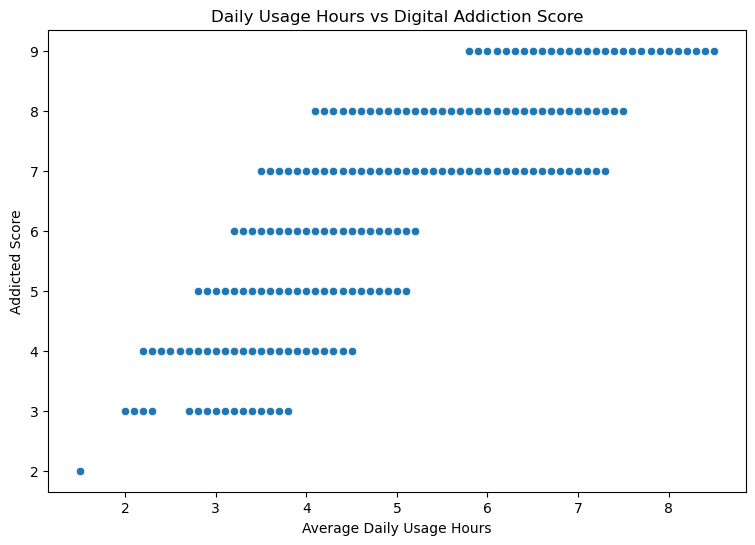

In [12]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Avg_Daily_Usage_Hours",
    y="Addicted_Score"
)

plt.title("Daily Usage Hours vs Digital Addiction Score")
plt.xlabel("Average Daily Usage Hours")
plt.ylabel("Addicted Score")

plt.show()

# Sleep vs addiction

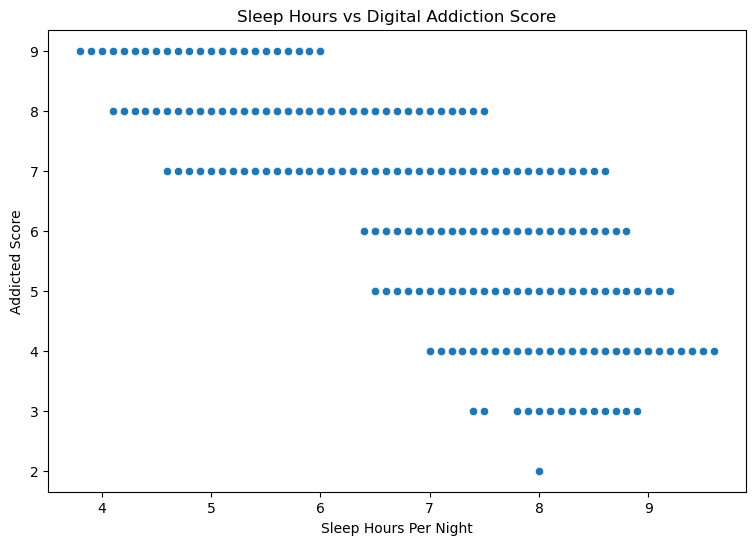

In [13]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Sleep_Hours_Per_Night",
    y="Addicted_Score"
)

plt.title("Sleep Hours vs Digital Addiction Score")
plt.xlabel("Sleep Hours Per Night")
plt.ylabel("Addicted Score")

plt.show()

# Mental health vs addiction

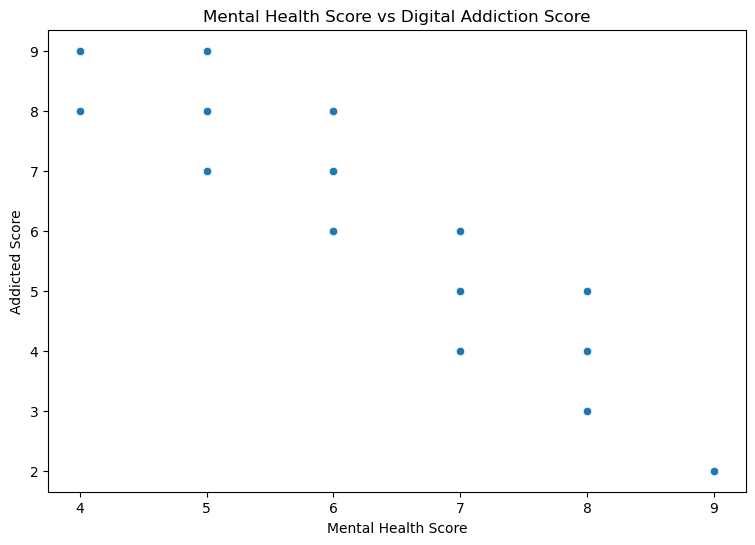

In [14]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Mental_Health_Score",
    y="Addicted_Score"
)

plt.title("Mental Health Score vs Digital Addiction Score")
plt.xlabel("Mental Health Score")
plt.ylabel("Addicted Score")

plt.show()

# Social-media conflicts vs addiction

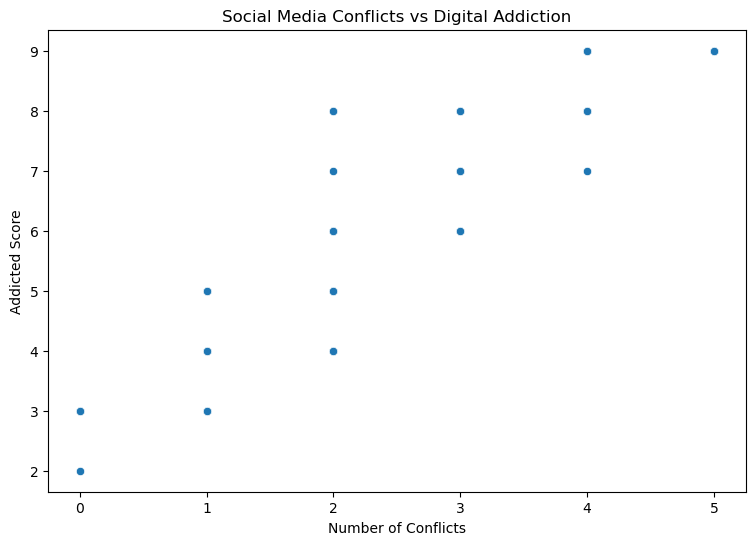

In [15]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="Conflicts_Over_Social_Media",
    y="Addicted_Score"
)

plt.title("Social Media Conflicts vs Digital Addiction")
plt.xlabel("Number of Conflicts")
plt.ylabel("Addicted Score")

plt.show()

# Platform analysis

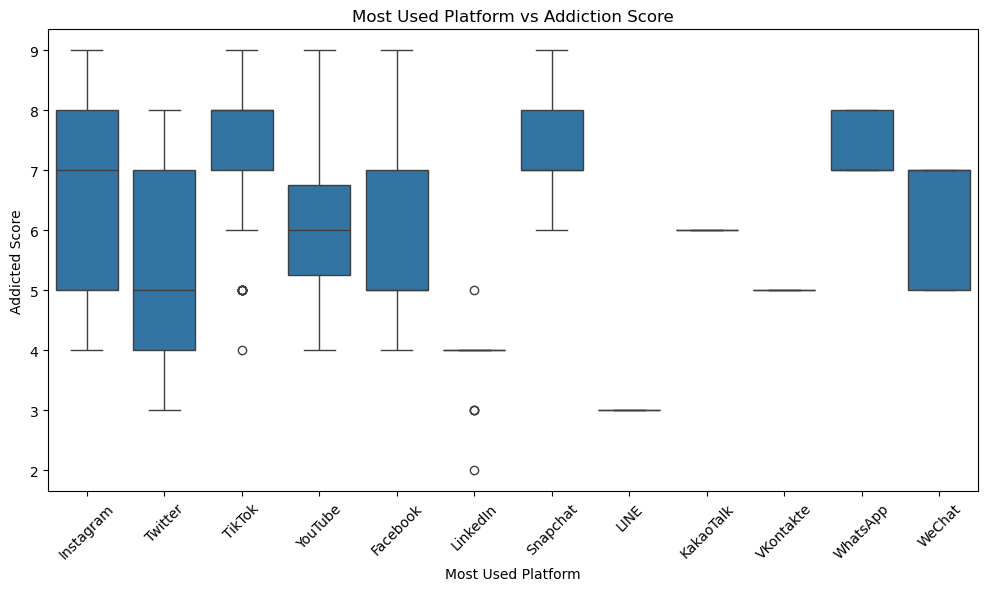

In [16]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="Most_Used_Platform",
    y="Addicted_Score"
)

plt.title("Most Used Platform vs Addiction Score")
plt.xlabel("Most Used Platform")
plt.ylabel("Addicted Score")

plt.xticks(rotation=45)

plt.show()

# Academic performance analysis

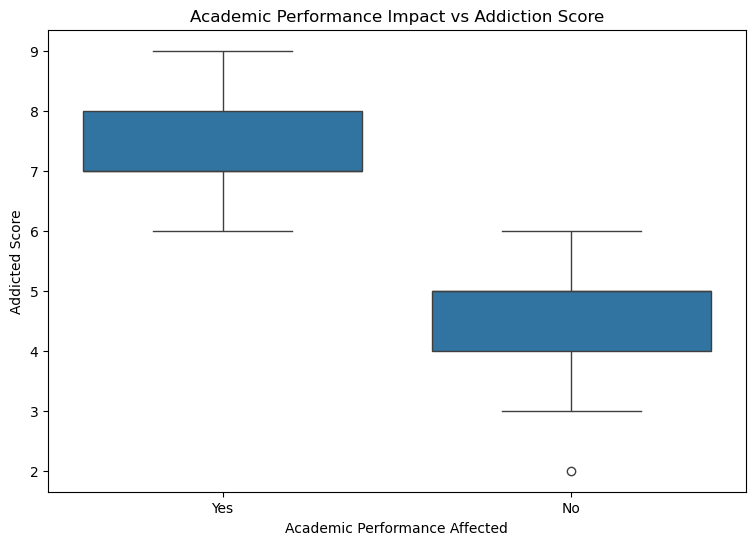

In [17]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="Affects_Academic_Performance",
    y="Addicted_Score"
)

plt.title("Academic Performance Impact vs Addiction Score")
plt.xlabel("Academic Performance Affected")
plt.ylabel("Addicted Score")

plt.show()

# Separate features and target

In [18]:
# Remove Student_ID
X = df.drop(
    columns=["Student_ID", "Addicted_Score"]
)

# Target
y = df["Addicted_Score"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features:
['Age', 'Gender', 'Academic_Level', 'Country', 'Avg_Daily_Usage_Hours', 'Most_Used_Platform', 'Affects_Academic_Performance', 'Sleep_Hours_Per_Night', 'Mental_Health_Score', 'Relationship_Status', 'Conflicts_Over_Social_Media']

Target:
Addicted_Score


# Identify categorical and numerical columns

In [19]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Age', 'Avg_Daily_Usage_Hours', 'Sleep_Hours_Per_Night', 'Mental_Health_Score', 'Conflicts_Over_Social_Media']

Categorical Features:
['Gender', 'Academic_Level', 'Country', 'Most_Used_Platform', 'Affects_Academic_Performance', 'Relationship_Status']


# Train-test split

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (564, 11)
Testing data: (141, 11)


# Preprocessing

In [21]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


# Model 1 Linear Regression

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(
    X_train,
    y_train
)

linear_predictions = linear_model.predict(
    X_test
)

print("Linear Regression trained successfully!")

Linear Regression trained successfully!


# Evaluate Linear Regression

In [23]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_predictions
    )
)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)

print("Linear Regression")
print("-------------------------")
print("MAE :", round(linear_mae, 4))
print("RMSE:", round(linear_rmse, 4))
print("R²  :", round(linear_r2, 4))

Linear Regression
-------------------------
MAE : 0.2215
RMSE: 0.3233
R²  : 0.9582


# Model 2 — Decision Tree

In [24]:
from sklearn.tree import DecisionTreeRegressor

decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeRegressor(
                max_depth=8,
                random_state=42
            )
        )
    ]
)

decision_tree_model.fit(
    X_train,
    y_train
)

decision_tree_predictions = (
    decision_tree_model.predict(X_test)
)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


# Evaluate Decision Tree

In [25]:
dt_mae = mean_absolute_error(
    y_test,
    decision_tree_predictions
)

dt_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        decision_tree_predictions
    )
)

dt_r2 = r2_score(
    y_test,
    decision_tree_predictions
)

print("Decision Tree")
print("-------------------------")
print("MAE :", round(dt_mae, 4))
print("RMSE:", round(dt_rmse, 4))
print("R²  :", round(dt_r2, 4))

Decision Tree
-------------------------
MAE : 0.0299
RMSE: 0.1689
R²  : 0.9886


# Model 3 — Random Forest

In [26]:
from sklearn.ensemble import RandomForestRegressor

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=300,
                max_depth=12,
                min_samples_split=4,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

random_forest_model.fit(
    X_train,
    y_train
)

random_forest_predictions = (
    random_forest_model.predict(X_test)
)

print("Random Forest trained successfully!")

Random Forest trained successfully!


# Evaluate Random Forest

In [27]:
rf_mae = mean_absolute_error(
    y_test,
    random_forest_predictions
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        random_forest_predictions
    )
)

rf_r2 = r2_score(
    y_test,
    random_forest_predictions
)

print("Random Forest")
print("-------------------------")
print("MAE :", round(rf_mae, 4))
print("RMSE:", round(rf_rmse, 4))
print("R²  :", round(rf_r2, 4))

Random Forest
-------------------------
MAE : 0.0547
RMSE: 0.1632
R²  : 0.9894


# Model 4 — Gradient Boosting

In [28]:
from sklearn.ensemble import GradientBoostingRegressor

gradient_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            GradientBoostingRegressor(
                n_estimators=200,
                learning_rate=0.05,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

gradient_model.fit(
    X_train,
    y_train
)

gradient_predictions = (
    gradient_model.predict(X_test)
)

print("Gradient Boosting trained successfully!")

Gradient Boosting trained successfully!


# Evaluate Gradient Boosting

In [29]:
gb_mae = mean_absolute_error(
    y_test,
    gradient_predictions
)

gb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        gradient_predictions
    )
)

gb_r2 = r2_score(
    y_test,
    gradient_predictions
)

print("Gradient Boosting")
print("-------------------------")
print("MAE :", round(gb_mae, 4))
print("RMSE:", round(gb_rmse, 4))
print("R²  :", round(gb_r2, 4))

Gradient Boosting
-------------------------
MAE : 0.0915
RMSE: 0.1778
R²  : 0.9874


# Compare all models

In [30]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],

    "MAE": [
        linear_mae,
        dt_mae,
        rf_mae,
        gb_mae
    ],

    "RMSE": [
        linear_rmse,
        dt_rmse,
        rf_rmse,
        gb_rmse
    ],

    "R2 Score": [
        linear_r2,
        dt_r2,
        rf_r2,
        gb_r2
    ]
})

results.sort_values(
    by="R2 Score",
    ascending=False
)

,Model,MAE,RMSE,R2 Score
2,Random Forest,0.054669,0.163197,0.989356
1,Decision Tree,0.029945,0.168949,0.988593
3,Gradient Boosting,0.091455,0.177838,0.987361
0,Linear Regression,0.221482,0.323265,0.958238


# Model comparison graph

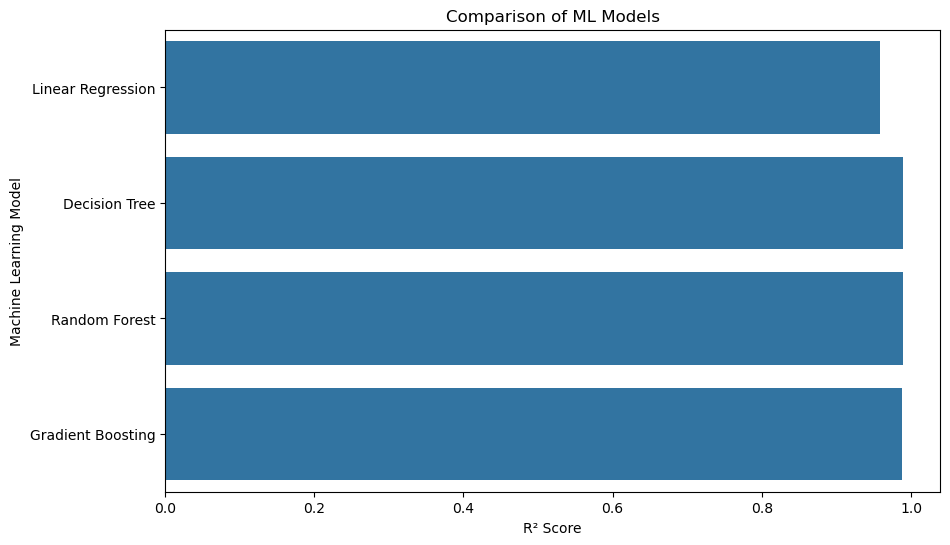

In [31]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results,
    x="R2 Score",
    y="Model"
)

plt.title("Comparison of ML Models")
plt.xlabel("R² Score")
plt.ylabel("Machine Learning Model")

plt.show()

# Find the best model

In [32]:
best_model_name = results.loc[
    results["R2 Score"].idxmax(),
    "Model"
]

print(
    "Best Model:",
    best_model_name
)

Best Model: Random Forest


# Actual vs Predicted

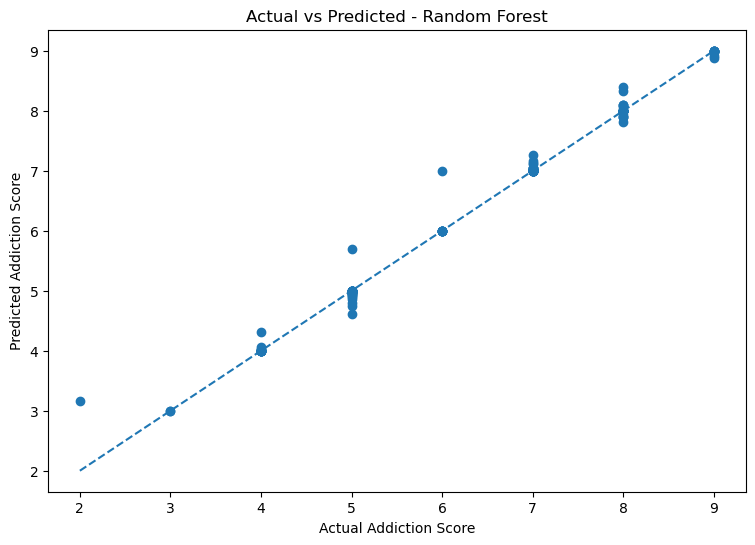

In [33]:
# Select predictions from best model

if best_model_name == "Linear Regression":
    best_predictions = linear_predictions
    best_model = linear_model

elif best_model_name == "Decision Tree":
    best_predictions = decision_tree_predictions
    best_model = decision_tree_model

elif best_model_name == "Random Forest":
    best_predictions = random_forest_predictions
    best_model = random_forest_model

else:
    best_predictions = gradient_predictions
    best_model = gradient_model


plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    best_predictions
)

plt.xlabel("Actual Addiction Score")
plt.ylabel("Predicted Addiction Score")

plt.title(
    f"Actual vs Predicted - {best_model_name}"
)

# Perfect prediction line
minimum = min(
    y_test.min(),
    best_predictions.min()
)

maximum = max(
    y_test.max(),
    best_predictions.max()
)

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.show()

# Prediction Error

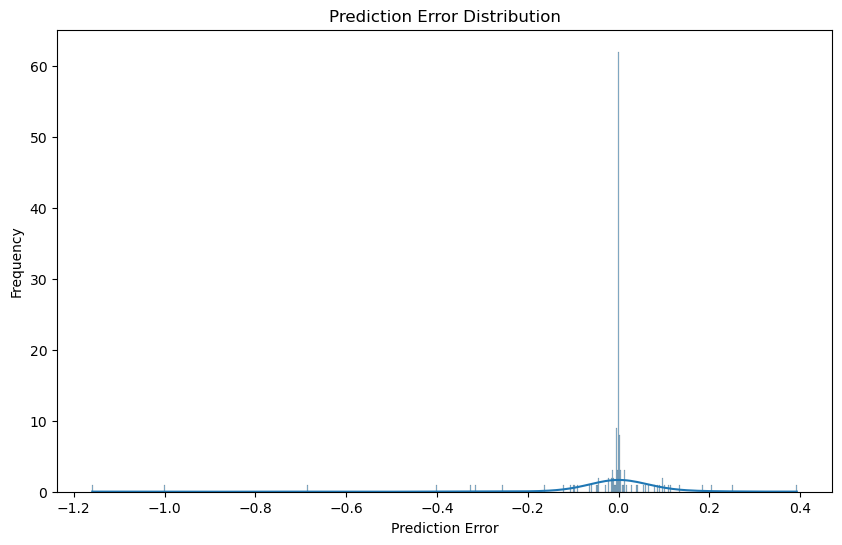

In [34]:
errors = y_test - best_predictions

plt.figure(figsize=(10, 6))

sns.histplot(
    errors,
    kde=True
)

plt.title(
    "Prediction Error Distribution"
)

plt.xlabel(
    "Prediction Error"
)

plt.ylabel(
    "Frequency"
)

plt.show()

# Feature Importance

In [35]:
if best_model_name in [
    "Decision Tree",
    "Random Forest",
    "Gradient Boosting"
]:

    model = best_model.named_steps["model"]

    processor = best_model.named_steps[
        "preprocessor"
    ]

    feature_names = (
        processor
        .get_feature_names_out()
    )

    importances = model.feature_importances_

    feature_importance = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    })

    feature_importance = (
        feature_importance
        .sort_values(
            by="Importance",
            ascending=False
        )
    )

    feature_importance.head(20)

# Feature importance graph

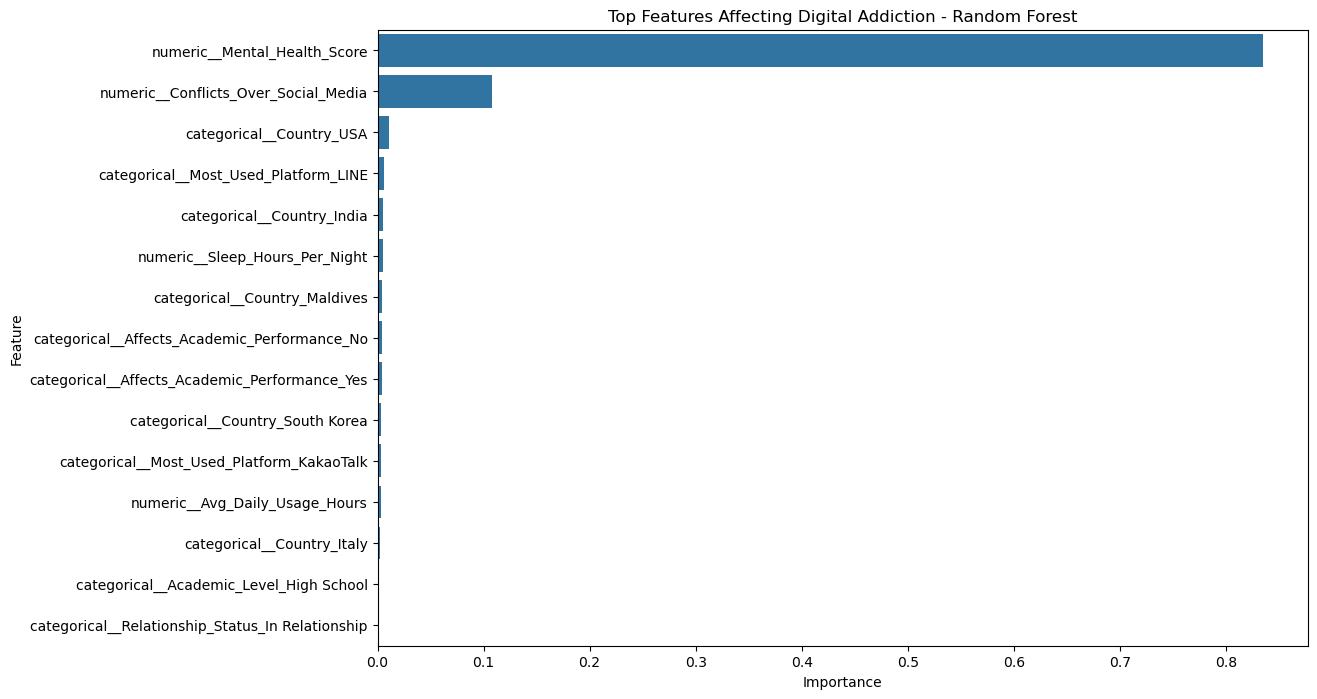

In [36]:
if best_model_name in [
    "Decision Tree",
    "Random Forest",
    "Gradient Boosting"
]:

    top_features = feature_importance.head(15)

    plt.figure(figsize=(12, 8))

    sns.barplot(
        data=top_features,
        x="Importance",
        y="Feature"
    )

    plt.title(
        f"Top Features Affecting Digital Addiction - "
        f"{best_model_name}"
    )

    plt.xlabel("Importance")
    plt.ylabel("Feature")

    plt.show()

# Predict a new student

In [37]:
print("Gender:")
print(df["Gender"].unique())

print("\nAcademic Level:")
print(df["Academic_Level"].unique())

print("\nCountry:")
print(df["Country"].unique())

print("\nPlatform:")
print(df["Most_Used_Platform"].unique())

print("\nAcademic Performance:")
print(df["Affects_Academic_Performance"].unique())

print("\nRelationship Status:")
print(df["Relationship_Status"].unique())

Gender:
['Female' 'Male']

Academic Level:
['Undergraduate' 'Graduate' 'High School']

Country:
['Bangladesh' 'India' 'USA' 'UK' 'Canada' 'Australia' 'Germany' 'Brazil'
 'Japan' 'South Korea' 'France' 'Spain' 'Italy' 'Mexico' 'Russia' 'China'
 'Sweden' 'Norway' 'Denmark' 'Netherlands' 'Belgium' 'Switzerland'
 'Austria' 'Portugal' 'Greece' 'Ireland' 'New Zealand' 'Singapore'
 'Malaysia' 'Thailand' 'Vietnam' 'Philippines' 'Indonesia' 'Taiwan'
 'Hong Kong' 'Turkey' 'Israel' 'UAE' 'Egypt' 'Morocco' 'South Africa'
 'Nigeria' 'Kenya' 'Ghana' 'Argentina' 'Chile' 'Colombia' 'Peru'
 'Venezuela' 'Ecuador' 'Uruguay' 'Paraguay' 'Bolivia' 'Costa Rica'
 'Panama' 'Jamaica' 'Trinidad' 'Bahamas' 'Iceland' 'Finland' 'Poland'
 'Romania' 'Hungary' 'Czech Republic' 'Slovakia' 'Croatia' 'Serbia'
 'Slovenia' 'Bulgaria' 'Estonia' 'Latvia' 'Lithuania' 'Ukraine' 'Moldova'
 'Belarus' 'Kazakhstan' 'Uzbekistan' 'Kyrgyzstan' 'Tajikistan' 'Armenia'
 'Georgia' 'Azerbaijan' 'Cyprus' 'Malta' 'Luxembourg' 'Monaco' 'Ando

# New student input

In [38]:
new_student = pd.DataFrame({
    "Age": [19],
    "Gender": [df["Gender"].iloc[0]],
    "Academic_Level": [df["Academic_Level"].iloc[0]],
    "Country": [df["Country"].iloc[0]],
    "Avg_Daily_Usage_Hours": [7.0],
    "Most_Used_Platform": [df["Most_Used_Platform"].iloc[0]],
    "Affects_Academic_Performance": [
        df["Affects_Academic_Performance"].iloc[0]
    ],
    "Sleep_Hours_Per_Night": [5.5],
    "Mental_Health_Score": [4.0],
    "Relationship_Status": [
        df["Relationship_Status"].iloc[0]
    ],
    "Conflicts_Over_Social_Media": [4]
})

new_student

,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status,Conflicts_Over_Social_Media
0,19,Female,Undergraduate,Bangladesh,7.0,Instagram,Yes,5.5,4.0,In Relationship,4


# Predict addiction score

In [39]:
predicted_score = best_model.predict(
    new_student
)[0]

# Keep prediction between 0 and 10
predicted_score = np.clip(
    predicted_score,
    0,
    10
)

print(
    "Predicted Addiction Score:",
    round(predicted_score, 2),
    "/ 10"
)

Predicted Addiction Score: 8.36 / 10


# Risk classification

In [40]:
def addiction_risk(score):

    if score < 3:
        return "Low Risk"

    elif score < 6:
        return "Moderate Risk"

    elif score < 8:
        return "High Risk"

    else:
        return "Very High Risk"


risk = addiction_risk(
    predicted_score
)

print(
    "Predicted Addiction Score:",
    round(predicted_score, 2),
    "/ 10"
)

print(
    "Risk Level:",
    risk
)

Predicted Addiction Score: 8.36 / 10
Risk Level: Very High Risk


# Personalized recommendations

In [41]:
def generate_recommendations(
    score,
    usage,
    sleep,
    academic_effect,
    conflicts
):

    recommendations = []

    if usage >= 6:
        recommendations.append(
            "Reduce daily digital/social-media usage."
        )

    if sleep < 6:
        recommendations.append(
            "Try to maintain approximately 7–8 hours "
            "of sleep per night."
        )

    if academic_effect == "Yes":
        recommendations.append(
            "Limit social-media usage during study hours."
        )

    if conflicts >= 3:
        recommendations.append(
            "Consider setting healthier boundaries "
            "for social-media use."
        )

    if score >= 8:
        recommendations.append(
            "Consider speaking with a trusted teacher, "
            "counselor, parent, or other appropriate support person."
        )

    if len(recommendations) == 0:
        recommendations.append(
            "Continue maintaining healthy digital habits."
        )

    return recommendations


recommendation_list = generate_recommendations(
    predicted_score,
    new_student["Avg_Daily_Usage_Hours"].iloc[0],
    new_student["Sleep_Hours_Per_Night"].iloc[0],
    new_student["Affects_Academic_Performance"].iloc[0],
    new_student["Conflicts_Over_Social_Media"].iloc[0]
)

print("Recommendations:")
for item in recommendation_list:
    print("-", item)

Recommendations:
- Reduce daily digital/social-media usage.
- Try to maintain approximately 7–8 hours of sleep per night.
- Limit social-media usage during study hours.
- Consider setting healthier boundaries for social-media use.
- Consider speaking with a trusted teacher, counselor, parent, or other appropriate support person.


# Save your trained model

In [42]:
joblib.dump(
    best_model,
    "student_digital_addiction_model.pkl"
)

print(
    "Model saved successfully!"
)

Model saved successfully!


# Load the model later

In [43]:
loaded_model = joblib.load(
    "student_digital_addiction_model.pkl"
)

print(
    "Model loaded successfully!"
)

Model loaded successfully!
